## Propeller-Nacelle Whirl Flutter
Houbolt & Reed, NASA Langley Research Center, 1962

This notebook reproduces the figures presented in the resource above. Particularly, those which lay down flutter and static divergence onset constraint curves for the purpose of design.

In [2]:
from scipy.optimize import root_scalar
from scipy.integrate import quad
import numpy as np 
import math
import matplotlib.pyplot as plt
plt.style.use("bmh")
try:
    plt.rcParams['font.family'] = 'Saira'
except: pass 

In [3]:
def whirl_flutter_eqs(k_theta, R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi, full_output=False):
    """solves the imaginary determinant expression for cantilever beam whirl flutter model 
    Key assumptions are that psi_1 = theta_1, M_1 = M_2, beta_psi = beta_theta, K_psi = n*K_theta, k_psi**2 = n*k_theta**2

    Args:
        vars (_type_): _description_
    """

    A_1 = quad(lambda eta: c_c0_func(eta)*(J_pi**2) / np.sqrt(J_pi**2 + eta**2), 0, 1)[0]
    A_1p = J_pi * A_1
    A_2 = quad(lambda eta: c_c0_func(eta)*(J_pi * eta**2) / np.sqrt(J_pi**2 + eta**2), 0, 1)[0]
    A_2p = J_pi * A_2
    A_3 = quad(lambda eta: c_c0_func(eta)*(eta**4) / np.sqrt(J_pi**2 + eta**2), 0, 1)[0]


    b_0 = (A_1 + (R_psi_1)**2*A_3)/mu
    delta_1 = 2*(beta_beta_cr)*sigma_1*k_theta*math.sqrt(n)
    e_1 = 0.5*(1/R_c_0)*(R_psi_1)**2*(k_P_R)**2
    a_0 = R_psi_1*A_1p/(2*mu*R_c_0)
    c_1 =R_psi_1**2*(1/R_c_0)*A_2p/(2*mu)


    A = sigma_1**2*((n-1)/2)**2
    B = ((n+1)/2)*((b_0 + delta_1)**2 + e_1**2)
    C = -((b_0 + delta_1)**2 + e_1**2)*(a_0/sigma_1 + c_1*e_1/(sigma_1*(b_0 + delta_1)) + c_1**2/((b_0 + delta_1)**2))

    if full_output: 
        return a_0, c_1, e_1, b_0, delta_1

    return A*k_theta**4 + B*k_theta**2 + C

def get_aero_and_system_terms(k_theta, R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi):
    A_1 = quad(lambda eta: c_c0_func(eta) * (J_pi**2) / np.sqrt(J_pi**2 + eta**2), 0, 1)[0]
    A_1p = J_pi * A_1
    A_2 = quad(lambda eta: c_c0_func(eta) * (J_pi * eta**2) / np.sqrt(J_pi**2 + eta**2), 0, 1)[0]
    A_2p = J_pi * A_2
    A_3 = quad(lambda eta: c_c0_func(eta) * (eta**4) / np.sqrt(J_pi**2 + eta**2), 0, 1)[0]

    b_0 = (A_1 + (R_psi_1**2) * A_3) / mu
    delta_1 = 2 * beta_beta_cr * sigma_1 * k_theta * math.sqrt(n)
    e_1 = 0.5 * (1 / R_c_0) * (R_psi_1**2) * (k_P_R**2)
    a_0 = R_psi_1 * A_1p / (2 * mu * R_c_0)
    c_1 = (R_psi_1**2) * (1 / R_c_0) * A_2p / (2 * mu)
    return a_0, b_0, c_1, e_1, delta_1

def whirl_flutter_eqs(k_theta, R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi):
    a_0, b_0, c_1, e_1, delta_1 = get_aero_and_system_terms(
        k_theta, R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi
    )
    B_term = (b_0 + delta_1)**2 + e_1**2
    A = sigma_1**2 * ((n - 1) / 2)**2
    B = ((n + 1) / 2) * B_term
    C = -B_term * (a_0 / sigma_1 + c_1 * e_1 / (sigma_1 * (b_0 + delta_1)) + c_1**2 / ((b_0 + delta_1)**2))
    return A * k_theta**4 + B * k_theta**2 + C

def static_divergence_k_theta_sq(R_psi_1, sigma_1, R_c_0, mu, n, c_c0_func, J_pi):
    # Setting k = 0 in Eq. (A8) gives: (sigma_1*n*k_theta^2 - a_0)*(sigma_1*k_theta^2 - a_0) + c_1^2 = 0
    a_0, _, c_1, _, _ = get_aero_and_system_terms(0.0, R_psi_1, 0.0, 0.0, sigma_1, R_c_0, mu, n, c_c0_func, J_pi)
    qa = n * sigma_1**2
    qb = -(n + 1) * sigma_1 * a_0
    qc = a_0**2 + c_1**2
    disc = qb**2 - 4 * qa * qc
    if disc < 0:
        return np.nan
    return (-qb + np.sqrt(disc)) / (2 * qa)

### Figure 3a

variation of whirl flutter frequency with advance ratio for the case of zero damping

In [4]:
# System 1 Parameters (Table 1)
n = 2 #ratio of pitch to yaw stiffness 
R_psi_1 = 0.585 #ratio of tip radius to yaw angle 
k_P_R = 1 / math.sqrt(3) #ratio of radius of gyration of propeller about spin axis to tip radius
sigma_1 = 1.90 #sigma 1 term 
R_c_0 = 4.5 #ratio of tip radius to reference chord 
mu = 150 #mass ratio 
c_c0_func = lambda eta: 1 #function defining chord distribution

J_pi_sweep = np.linspace(0.01, 2, 100)
results = {}

for beta_beta_cr in [0, 0.02]:
    k_theta_sq_list = []
    omega_ratio_list = []

    for J_pi in J_pi_sweep:
        sol = root_scalar(
            whirl_flutter_eqs,
            bracket=[0.0, 0.05],
            method='brentq',
            args=(R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi)
        )
        k_theta = sol.root
        a_0, b_0, c_1, e_1, delta_1 = get_aero_and_system_terms(
            k_theta, R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi
        )

        # Solve imaginary part of (A8) for k^2
        k_sq = ((n + 1) / 2) * k_theta**2 - (a_0 / sigma_1) - (c_1 * e_1) / (sigma_1 * (b_0 + delta_1))

        if k_sq >= 0:
            k_theta_sq_list.append(k_theta**2)
            omega_ratio_list.append(math.sqrt(k_sq) / k_theta)
        else:
            k_theta_sq_list.append(np.nan)
            omega_ratio_list.append(np.nan)

    results[beta_beta_cr] = (np.array(k_theta_sq_list), np.array(omega_ratio_list))

div_curve = np.array([static_divergence_k_theta_sq(R_psi_1, sigma_1, R_c_0, mu, n, c_c0_func, J) for J in J_pi_sweep])

findfont: Failed to find font weight normal for Saira, now using 100.


C:\Users\shay_streamline\AppData\Local\Temp\ipykernel_15376\3830396522.py:15: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-." (-> color='k'). The keyword argument will take precedence.
  ax2.plot(J_pi_sweep, div_curve, 'k-.', label='Divergence', color="red")
findfont: Failed to find font weight normal for Saira, now using 100.
findfont: Failed to find font weight normal for Saira, now using 100.
findfont: Failed to find font weight normal for Saira, now using 100.


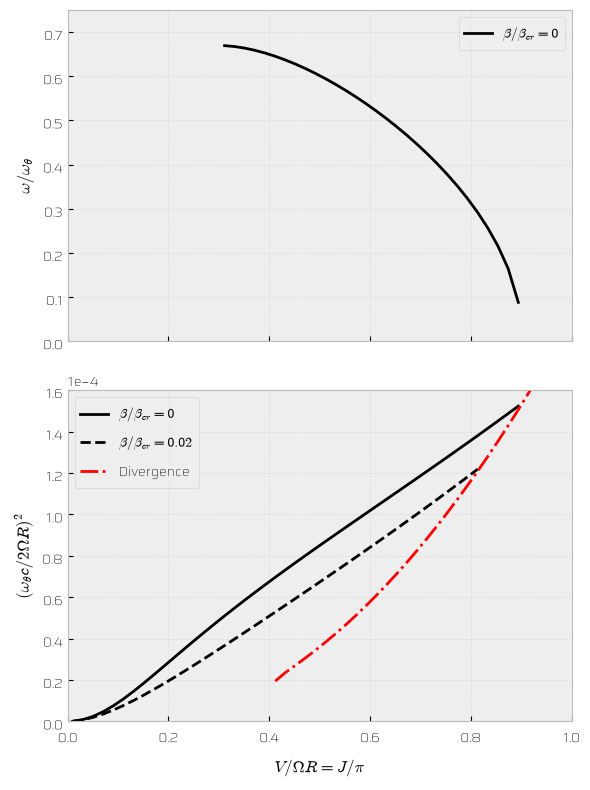

In [5]:
# Plot Figure 3
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 8), sharex=True)

# Top plot: omega / omega_theta for zero damping
mask_top = J_pi_sweep >= 0.30
ax1.plot(J_pi_sweep[mask_top], results[0][1][mask_top], 'k-', label=r'$\beta/\beta_{cr} = 0$')
ax1.set_ylabel(r'$\omega / \omega_\theta$')
ax1.set_ylim(0, 0.75)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Bottom plot: (omega_theta * c / 2*Omega*R)^2 = k_theta^2
ax2.plot(J_pi_sweep, results[0][0], 'k-', label=r'$\beta/\beta_{cr} = 0$')
ax2.plot(J_pi_sweep, results[0.02][0], 'k--', label=r'$\beta/\beta_{cr} = 0.02$')
ax2.plot(J_pi_sweep, div_curve, 'k-.', label='Divergence', color="red")
ax2.set_xlabel(r'$V / \Omega R = J / \pi$')
ax2.set_ylabel(r'$(\omega_\theta c / 2\Omega R)^2$')
ax2.set_xlim(0, 1.0)
ax2.set_ylim(0, 1.6e-4)
ax2.ticklabel_format(axis='y', style='sci', scilimits=(-4, -4))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Figure 5a 
Critical pitch stiffness in the pitch and yaw directions



In [6]:
n_sweep = np.linspace(0.2, 5, 100)
J_pi = 0.6
beta_beta_cr = 0

k_theta_list = []
k_psi_list = []

k_theta_div_list = []
k_psi_div_list = []

for n in n_sweep:
        sol = root_scalar(
            whirl_flutter_eqs,
            bracket=[0.0, 1],
            method='brentq',
            args=(R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi)
        )
        k_theta = sol.root
        a_0, b_0, c_1, e_1, delta_1 = get_aero_and_system_terms(
            k_theta, R_psi_1, beta_beta_cr, k_P_R, sigma_1, R_c_0, mu, n, c_c0_func, J_pi
        )   

        #calculate k_theta for k = 0 condition 
        k_theta_div = static_divergence_k_theta_sq(R_psi_1, sigma_1, R_c_0, mu, n, c_c0_func, J_pi)

        k_theta_list.append(k_theta**2)
        k_psi_list.append(k_theta**2*n)

        k_theta_div_list.append(k_theta_div)
        k_psi_div_list.append(k_theta_div*n)


[]

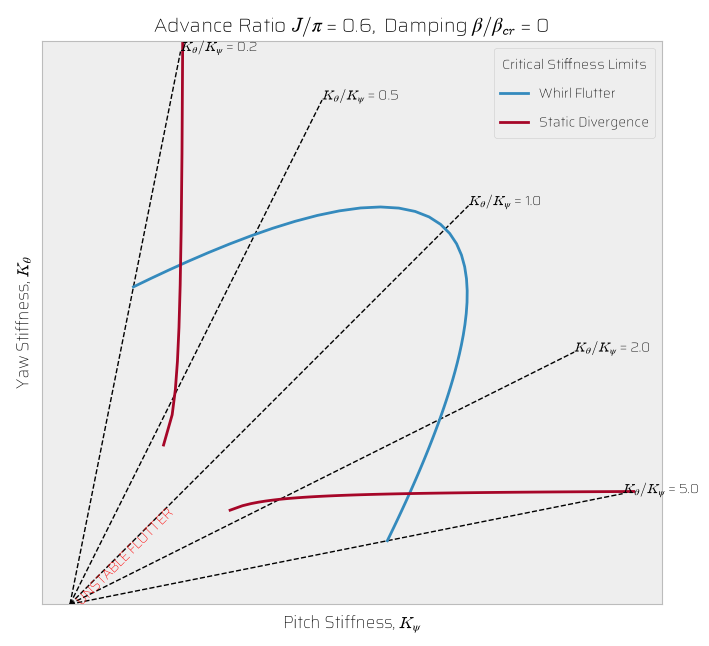

In [15]:
fig, ax = plt.subplots(1,1,figsize=(8,8))
ax.set_aspect("equal")

x = np.linspace(0, max(k_psi_div_list), 100)
slopes = [0.2, 0.5, 1, 2, 5]
angs = np.atan(slopes)
L = max([max(k_theta_div_list), max(k_theta_list)])

for i,ang in enumerate(angs):
    ax.plot([0, L*np.cos(ang)], [0, L*np.sin(ang)], linestyle="dashed", color="black", linewidth=1, label="_nolegend_")
    ax.annotate(text="$K_{\u03B8}/K_{\u03C8}$ = " + f"{1/slopes[i]}", xy=[L*np.cos(ang), L*np.sin(ang)])

ax.plot(k_psi_list, k_theta_list, label="Whirl Flutter")
ax.plot(k_psi_div_list, k_theta_div_list, label="Static Divergence")
ax.annotate(text="UNSTABLE FLUTTER", xy=[0, 0], color="red", rotation=45)
ax.set_xlabel("Pitch Stiffness, $K_{\u03C8}$")
ax.set_ylabel("Yaw Stiffness, $K_{\u03B8}$")
ax.set_ylim([0, max(k_theta_div_list)])
ax.legend(loc="best", title="Critical Stiffness Limits")
ax.set_title("Advance Ratio $J/{\u03C0}$ = " + f"{J_pi}" + ",  Damping ${\u03B2}/{\u03B2}_{cr}$ = " + f"{beta_beta_cr}")
ax.set_xticks([])
ax.set_yticks([])